# Preprosesing data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Import data cần xử lý vào

Chúng ta sẽ làm việc với 3 file data chính là calendar, prices, sales.

Tập prices chứa các cột về giá cả của từng mặt hàng, sales chứa thông tin về doanh số từng ngày từ d_1 -> d_1968 với định dạng là ngang, calendar thì chứa thông tin ngày tháng thôi

In [ ]:
path = "../data"

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

Hàm prep_calendar:

* Xoá cột không cần thiết.

* Chuyển cột d về số nguyên.

* Mã hóa các tên sự kiện thành số nguyên.

* Ép kiểu các cột số để tiết kiệm bộ nhớ.

In [ ]:
def prep_calendar(df):
    df = df.drop(["weekday", "event_type_1", "event_type_2"], axis=1)
    df = df.assign(d = df.d.str[2:].astype(int))
    to_ordinal = ["event_name_1", "event_name_2"] 
    df[to_ordinal] = df[to_ordinal].fillna("1")
    df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
    to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
    df[to_int8] = df[to_int8].astype("int8")
    
    return df

calendar = prep_calendar(calendar)
calendar.head()

,date,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,1,1,2011,1,1,1,0,0,0
1,2011-01-30,11101,2,1,2011,2,1,1,0,0,0
2,2011-01-31,11101,3,1,2011,3,1,1,0,0,0
3,2011-02-01,11101,4,2,2011,4,1,1,1,1,0
4,2011-02-02,11101,5,2,2011,5,1,1,1,0,1


### 🧠 Hàm `downcast(df)` – Giảm kích thước DataFrame

Hàm này giúp **tối ưu bộ nhớ** bằng cách ép kiểu dữ liệu các cột sang dạng nhỏ nhất phù hợp, mà vẫn giữ nguyên giá trị.

---

#### ✅ Mục đích:
- Giảm dung lượng bộ nhớ RAM khi làm việc với dữ liệu lớn.
- Tăng hiệu suất xử lý.

---

#### 🔍 Cách hoạt động:

1. **Lặp qua từng cột trong DataFrame**.
2. Nếu là **kiểu số nguyên (`int`)**:
   - Ép kiểu thành `int8`, `int16`, `int32`, hoặc `int64` tùy theo giá trị min/max.
3. Nếu là **kiểu số thực (`float`)**:
   - Ép kiểu thành `float32` nếu phù hợp.
   - Tránh dùng `float16` (vì không tương thích với Parquet).
4. Nếu là **chuỗi (`object`)**:
   - Nếu cột tên là `date` → chuyển thành `datetime`.
   - Các cột khác → chuyển thành `category`. ( phần này thì sẽ cân nhắc, vì cần tính tới mức độ cần thiết và không làm mất đi data quan trọng)


In [5]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

Chạy hàm downcast cho cả 3 bộ dataset

In [ ]:
# Calculate memory usage before running the function
memory_before = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

sales = downcast(sales)
prices = downcast(prices)
calendar = downcast(calendar)

memory_after = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

Plot ra sự so sánh giữa trước và sau khi downcast để chứng minh rằng việc downcast là cần thiết và có ý nghĩa

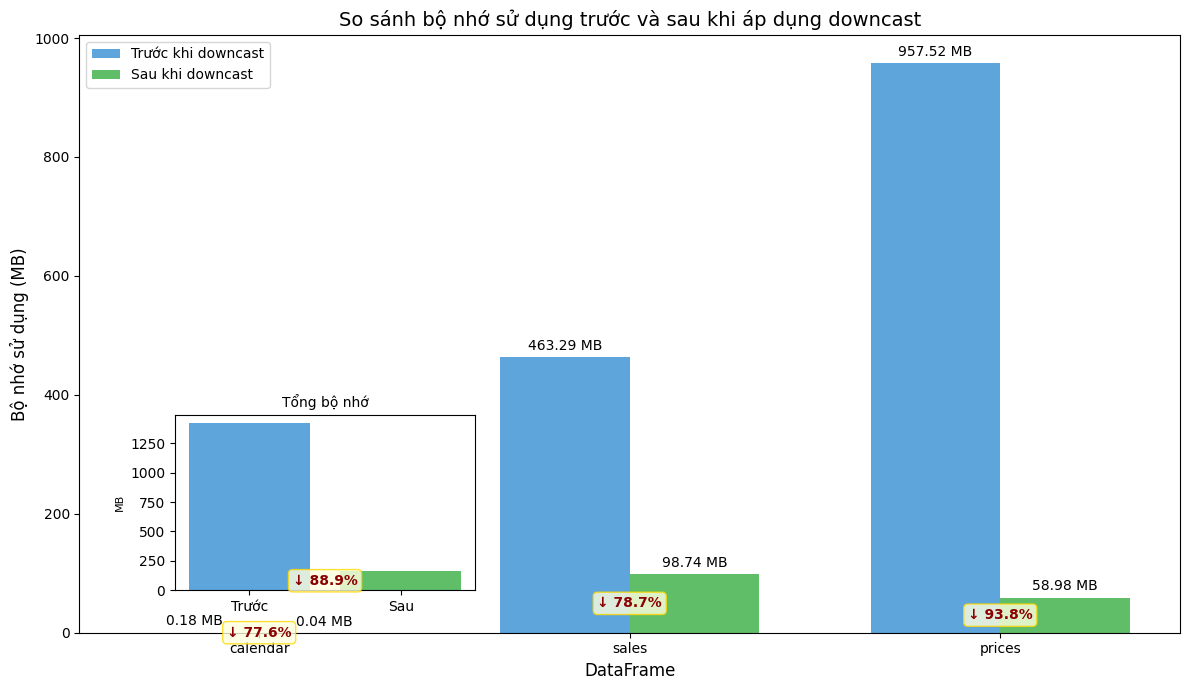


Thông tin chi tiết về bộ nhớ sử dụng:
DataFrame  Trước (MB)      Sau (MB)        Giảm (MB)       Giảm (%)  
----------------------------------------------------------------------
calendar   0.18            0.04            0.14            77.6      
sales      463.29          98.74           364.56          78.7      
prices     957.52          58.98           898.54          93.8      
----------------------------------------------------------------------
TỔNG       1420.99         157.76          1263.23         88.9      


In [ ]:
def plot_memory_comparison(memory_before, memory_after):
    """
    Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
    Parameters:
    -----------
    memory_before : dict
        Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
    memory_after : dict
        Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
    """
    
    # Lấy tên của các DataFrame
    df_names = list(memory_before.keys())
    
    # Tính toán giá trị bộ nhớ ở MB
    before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
    after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
    # Tính phần trăm giảm bộ nhớ
    reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
    # Thiết lập vị trí của các cột
    x = np.arange(len(df_names))
    width = 0.35
    
    # Tạo biểu đồ
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Vẽ cột
    rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
    rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
    # Thêm nhãn, tiêu đề và các thông tin khác
    ax.set_xlabel('DataFrame', fontsize=12)
    ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
    ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(df_names)
    ax.legend()
    
    # Thêm giá trị lên mỗi cột
    def add_labels(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f} MB',
                         xy=(rect.get_x() + rect.get_width() / 2, height),
                         xytext=(0, 3),  # 3 points vertical offset
                         textcoords="offset points",
                         ha='center', va='bottom')
    
    add_labels(rects1)
    add_labels(rects2)
    
    # Thêm phần trăm giảm bộ nhớ
    for i, pct in enumerate(reduction_pct):
        ax.annotate(f'↓ {pct:.1f}%',
                    xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
                    xytext=(0, 0),
                    textcoords="offset points",
                    ha='center', va='center',
                    color='darkred',
                    fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.tight_layout()
    
    # Thêm biểu đồ tổng hợp
    ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
    total_before = sum(before_mb)
    total_after = sum(after_mb)
    total_reduction = (total_before - total_after) / total_before * 100
    
    ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
    ax2.set_title('Tổng bộ nhớ', fontsize=10)
    ax2.set_ylabel('MB', fontsize=8)
    ax2.annotate(f'↓ {total_reduction:.1f}%', 
                xy=(0.5, min(total_before, total_after) / 2),
                xytext=(0, 0),
                textcoords="offset points",
                ha='center', va='center',
                color='darkred',
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.show()
    
    # In thông tin chi tiết
    print("\nThông tin chi tiết về bộ nhớ sử dụng:")
    print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
    print("-" * 70)
    
    for i, name in enumerate(df_names):
        reduced = memory_before[name] - memory_after[name]
        reduced_mb = reduced / (1024 * 1024)
        print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
    print("-" * 70)
    total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
    print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# Sử dụng hàm
plot_memory_comparison(memory_before, memory_after)

### 💾 Vì sao nên lưu file dưới dạng `.parquet` thay vì `.csv`?

- **Dung lượng nhỏ hơn** nhờ hỗ trợ nén và lưu trữ theo cột.
- **Tốc độ đọc/ghi nhanh hơn** nhiều so với `.csv`.
- **Giữ nguyên kiểu dữ liệu** (dtype), không cần xử lý lại sau khi load.
- **Linh hoạt khi xử lý**, chỉ cần đọc các cột cần thiết.


In [ ]:
calendar.to_parquet('done_cal.parquet')
sales.to_parquet('done_sales.parquet')
prices.to_parquet('done_prices.parquet')

In [ ]:
calendar

,date,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,1,1,2011,1,1,1,0,0,0
1,2011-01-30,11101,2,1,2011,2,1,1,0,0,0
2,2011-01-31,11101,3,1,2011,3,1,1,0,0,0
3,2011-02-01,11101,4,2,2011,4,1,1,1,1,0
4,2011-02-02,11101,5,2,2011,5,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1964,2016-06-15,11620,5,6,2016,1965,1,1,0,1,1
1965,2016-06-16,11620,6,6,2016,1966,1,1,0,0,0
1966,2016-06-17,11620,7,6,2016,1967,1,1,0,0,0
1967,2016-06-18,11621,1,6,2016,1968,1,1,0,0,0


Sau mỗi lần dùng và tạo ra df mà không cần sử dụng nữa thì ta dùng del và gc.collect() để xóa bộ nhớ

In [ ]:
import gc
del calendar, prices, sales
gc.collect()

5631

# Xử lí dữ liệu disasater để thêm một cột dữ liệu cho df gốc.

Quy tắc là thêm một cột disaster_severity_flag nhằm biểu thị mức độ nghiệm trọng của thiên tai ảnh hưởng tới doanh thu của hàng hóa, nếu doanh thu ít mà trong ngày đó xảy ra thiên tai thì chứng tỏ thiên tai có ảnh hưởng nghiêm trọng tới doanh thu, doanh thu càng thấp thì flag có giá trị càng cao và ngược lại, ở đây nhóm em đề xuất sử dụng thang đo là 15( có thể thử nghiệm thêm nhiều thang đo tùy thôi, test nhiều thang để biết thang nào có hiệu suất cao nhất)

In [14]:
disater = pd.read_csv('../data/us_disasters_m5.csv')

def prep_disater(disater):
    done_dis = disater[['state', 'incident_type', 'incident_begin_date', 'incident_end_date']].copy()
    
    # Chuyển đổi kiểu datetime
    done_dis['incident_begin_date'] = pd.to_datetime(done_dis['incident_begin_date'], errors='coerce')
    done_dis['incident_end_date'] = pd.to_datetime(done_dis['incident_end_date'], errors='coerce')
    
    # Thay thế giá trị thiếu trong incident_end_date
    done_dis['incident_end_date'] = done_dis['incident_end_date'].fillna(
        done_dis['incident_begin_date'] + pd.Timedelta(days=1)
    )
    
    done_dis['incident_begin_date'] = done_dis['incident_begin_date'].dt.tz_localize(None)
    done_dis['incident_end_date'] = done_dis['incident_end_date'].dt.tz_localize(None)
    
    return done_dis

done_dis = prep_disater(disater)

print(done_dis['incident_type'].unique())
print(done_dis['state'].unique())

from sklearn.preprocessing import LabelEncoder

# B1: Gắn tên bang từ state_id để khớp done_dis
label_encoder = LabelEncoder()
done_dis['state'] = label_encoder.fit_transform(done_dis['state'])+1

done_dis.to_parquet('../data/done_dis.parquet')

['Fire' 'Snow' 'Tsunami' 'Severe Storm(s)' 'Other' 'Earthquake' 'Flood']
['TX' 'WI' 'CA']


In [15]:
import gc
del done_dis, disater
gc.collect()

0

In [2]:
calendar = pd.read_parquet('done_cal.parquet')

prices = pd.read_parquet('done_prices.parquet')

sales = pd.read_parquet('done_sales.parquet')

done_dis = pd.read_parquet('../data/done_dis.parquet')

# Merge data giữa sales, calendar và prices


1. **Hàm `demand_features(df)`:**
   - Tạo các features dựa trên lịch sử nhu cầu
   - Tính toán giá trị lag (trễ) cho mỗi sản phẩm
   - Tính trung bình động (rolling mean) cho các giá trị lag

2. **Hàm `prep_data(df, drop_d=1000)`:**
   - Loại bỏ dữ liệu cũ trước ngày `drop_d`
   - Chuyển dữ liệu từ dạng rộng (wide) sang dạng dài (long)
   - Tạo features từ dữ liệu nhu cầu (demand)
   - Kết hợp với dữ liệu lịch (calendar) và giá (prices)
   - Mã hóa các biến phân loại (categorical) thành dạng số

In [3]:
from sklearn.model_selection import train_test_split

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """
    
    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
    return df

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """
    
    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))
    
    # Add demand features
    df = demand_features(df)
    
    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)
    
    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
    return df

df = prep_data(sales, 1000 - 28)
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')

4097.29 MB


### Code này để thêm features flag disater như đã phân tích ở trên

In [7]:
# B3: Khởi tạo cột disaster_type (ban đầu là None)
df['disaster_type'] = None

# B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
for _, row in done_dis.iterrows():
    mask = (
        (df['state_id'] == row['state']) &
        (df['date'] >= row['incident_begin_date']) &
        (df['date'] <= row['incident_end_date'])
    )
    df.loc[mask, 'disaster_type'] = row['incident_type']

# B5: Tính tổng doanh thu theo loại thảm họa
revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

# B6: Chuẩn hóa giá trị doanh thu để gán severity flag
# doanh thu càng thấp => mức độ ảnh hưởng càng nặng
rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
max_rank = rank.max()
severity_map = (rank / max_rank * 15).astype(int)  # chia thành 1–15

# B7: Gán cột flag theo loại thảm họa
df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0


In [ ]:
import gc
del calendar, prices, sales # sau khi dùng xong và không cần dùng lại thì xóa đi cho đỡ chiếm bộ nhớnhớ
gc.collect()
df['state_id'].unique()
done_dis['state'].unique()

0

In [8]:
print(df.columns)
print(df['disaster_severity_flag'].unique())

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag'],
      dtype='object')
[ 0 15  3  7 11]


In [13]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.preprocessing import StandardScaler, MinMaxScaler
# import os
# import tensorflow as tf
# from sklearn.preprocessing import OrdinalEncoder
# import lightgbm as lgb
# import os, sys, gc, time, warnings, pickle, psutil, random
# from tqdm import tqdm
# from math import ceil
# from sklearn.preprocessing import LabelEncoder
# from sklearn.model_selection import train_test_split
# import math
# from statsmodels.tsa.seasonal import STL
# from scipy import stats
# print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
# print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

data = pd.read_parquet('../data/train_val.parquet')
print(data.columns)
print(data['disaster_severity_flag'].unique())
print(data['id'].unique())
print(len(data['id']))

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc'],
      dtype='object')
[ 0 15  3  7 11]
['HOBBIES_1_001_CA_1' 'HOBBIES_1_002_CA_1' 'HOBBIES_1_003_CA_1' ...
 'FOODS_3_825_WI_3' 'FOODS_3_826_WI_3' 'FOODS_3_827_WI_3']
28691090


**Xử lý outlier:** 
* Xác định danh sách ID duy nhất trong dữ liệu
* Duyệt qua từng ID:
  * In tiến độ sau mỗi 1000 ID
  * Lọc dữ liệu theo ID
  * Tạo dataframe chuỗi thời gian với date và demand
  * Tính Exponential Moving Average (EMA)
  * Phát hiện outlier bằng một trong hai cách:
     * Nếu đủ dữ liệu (≥ 2*period): Dùng STL để phân tách xu hướng và mùa vụ, sau đó tìm outlier trong phần dư
     * Nếu không đủ dữ liệu: Áp dụng z-score trực tiếp lên giá trị demand
  * Thay thế các giá trị outlier bằng giá trị EMA tương ứng

In [7]:
# Giả định df là dataframe của bạn đã có sẵn date
# df cần có các cột: 'id', 'date', 'demand'

minh  = 10000000
phuoc = 20000000

min = 5000
dung = 'con bò'

# thay là minh thì [:minh] phước là [minh+1:phuoc] dũng là [phuoc+1:]

df = data[:][:min]

# Danh sách các ID cần xử lý

print('kiki')

id_list = df['id'].unique()

cnt = 0
for instance in id_list:
    cnt += 1
    if cnt % 1000 == 0:
        print(f"Đã xử lý {cnt} ID")
    
    # Lọc dữ liệu theo ID
    filtered_df = df[df.id == instance]
    
    # Tạo DataFrame cho chuỗi thời gian sales
    sales_ts = pd.DataFrame({
        'date': filtered_df['date'].values,
        'demand': filtered_df['demand'].values
    })
    
    # Tính Exponential Moving Average (EMA)
    sales_ts['EMA'] = sales_ts['demand'].ewm(span=2, adjust=False).mean()
    sales_ts['EMA'] = sales_ts['EMA'].apply(math.ceil)
    
    # Phân tích chuỗi thời gian theo mùa vụ
    # Xác định period phù hợp với dữ liệu của bạn (7 cho tuần, 30 cho tháng)
    period = 30  # Điều chỉnh tùy theo dữ liệu của bạn
    
    # Xử lý trường hợp dữ liệu quá ngắn cho STL
    if len(sales_ts) >= 2 * period:
        stl = STL(sales_ts['demand'], period=period)
        res = stl.fit()
        residual = res.resid
        
        # Áp dụng z-score để tìm outlier trong residual
        z = np.abs(stats.zscore(residual))
        threshold = 2.8  # ngưỡng z-score
        outliers = sales_ts[z > threshold]
        
        # Thay thế các giá trị ngoại lai bằng giá trị EMA
        for idx, row in outliers.iterrows():
            df.loc[(df.id == instance) & (df['date'] == row['date']), 'demand'] = row['EMA']
    else:
        # Nếu dữ liệu quá ngắn cho STL, có thể dùng phương pháp z-score trực tiếp
        z = np.abs(stats.zscore(sales_ts['demand']))
        threshold = 2.8
        outliers = sales_ts[z > threshold]
        
        for idx, row in outliers.iterrows():
            df.loc[(df.id == instance) & (df['date'] == row['date']), 'demand'] = row['EMA']

print(f"Đã xử lý tất cả {cnt} ID và điều chỉnh các outlier")

kiki
Đã xử lý 1000 ID
Đã xử lý 2000 ID
Đã xử lý 3000 ID
Đã xử lý 4000 ID
Đã xử lý 5000 ID
Đã xử lý tất cả 5000 ID và điều chỉnh các outlier


## Phân tích trước và sau khi xử lý outlier

In [ ]:
# import gc
# gc.collect()

79

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from scipy import stats
import math
import random

# Giả sử bạn đã có code xử lý outlier như trên
# Giờ ta sẽ thêm code để lưu dữ liệu gốc và hiển thị biểu đồ

def process_outliers_with_visualization(data):
    """
    Xử lý outliers và tạo biểu đồ so sánh trước và sau xử lý
    """
    minh = 100000
    # Tạo bản sao dữ liệu
    df_original = data[:][:minh].copy()
    df = data[:][:minh].copy()

    
    # Danh sách các ID cần xử lý
    id_list = df['id'].unique()
    
    # Lưu thông tin về outlier để vẽ biểu đồ sau
    all_outliers = []
    
    cnt = 0
    for instance in id_list:
        cnt += 1
        if cnt % 1000 == 0:
            print(f"Đã xử lý {cnt} ID")
        
        # Lọc dữ liệu theo ID
        filtered_df = df[df.id == instance]
        
        # Tạo DataFrame cho chuỗi thời gian sales
        sales_ts = pd.DataFrame({
            'date': filtered_df['date'].values,
            'demand': filtered_df['demand'].values
        })
        
        # Tính Exponential Moving Average (EMA)
        sales_ts['EMA'] = sales_ts['demand'].ewm(span=2, adjust=False).mean()
        sales_ts['EMA'] = sales_ts['EMA'].apply(math.ceil)
        
        # Phân tích chuỗi thời gian theo mùa vụ
        period = 30  # Điều chỉnh tùy theo dữ liệu của bạn
        
        outliers_info = None
        
        # Xử lý trường hợp dữ liệu quá ngắn cho STL
        if len(sales_ts) >= 2 * period:
            stl = STL(sales_ts['demand'], period=period)
            res = stl.fit()
            residual = res.resid
            
            # Áp dụng z-score để tìm outlier trong residual
            z = np.abs(stats.zscore(residual))
            threshold = 2.8  # ngưỡng z-score
            outliers = sales_ts[z > threshold]
            outliers_info = outliers.copy()
            
            # Thay thế các giá trị ngoại lai bằng giá trị EMA
            for idx, row in outliers.iterrows():
                df.loc[(df.id == instance) & (df['date'] == row['date']), 'demand'] = row['EMA']
        else:
            # Nếu dữ liệu quá ngắn cho STL, có thể dùng phương pháp z-score trực tiếp
            z = np.abs(stats.zscore(sales_ts['demand']))
            threshold = 2.8
            outliers = sales_ts[z > threshold]
            outliers_info = outliers.copy()
            
            for idx, row in outliers.iterrows():
                df.loc[(df.id == instance) & (df['date'] == row['date']), 'demand'] = row['EMA']
                
        # Lưu thông tin về các outlier để vẽ biểu đồ
        if outliers_info is not None and not outliers_info.empty:
            outliers_info['id'] = instance
            all_outliers.append(outliers_info)
    
    print(f"Đã xử lý tất cả {cnt} ID và điều chỉnh các outlier")
    
    # Tổng hợp tất cả các outlier
    if all_outliers:
        all_outliers_df = pd.concat(all_outliers)
        print(f"Tìm thấy tổng cộng {len(all_outliers_df)} outliers")
    else:
        all_outliers_df = pd.DataFrame()
        print("Không tìm thấy outlier nào")
    
    return df, df_original, all_outliers_df

def plot_outliers_comparison(df_original, df_processed, outliers_df, num_samples=5):
    """
    Vẽ biểu đồ so sánh trước và sau khi xử lý outlier
    """
    if outliers_df.empty:
        print("Không có outlier để hiển thị")
        return
    
    # Lấy mẫu ngẫu nhiên các ID có chứa outlier để vẽ biểu đồ
    unique_ids_with_outliers = outliers_df['id'].unique()
    
    if len(unique_ids_with_outliers) > num_samples:
        sample_ids = random.sample(list(unique_ids_with_outliers), num_samples)
    else:
        sample_ids = unique_ids_with_outliers
    
    for id_to_plot in sample_ids:
        # Lọc dữ liệu theo ID
        orig_data = df_original[df_original.id == id_to_plot]
        proc_data = df_processed[df_processed.id == id_to_plot]
        outliers = outliers_df[outliers_df.id == id_to_plot]
        
        # Sắp xếp theo ngày
        orig_data = orig_data.sort_values('date')
        proc_data = proc_data.sort_values('date')
        
        # Vẽ biểu đồ
        plt.figure(figsize=(14, 6))
        
        # Subplot 1: Dữ liệu gốc với các outlier được đánh dấu
        plt.subplot(1, 2, 1)
        plt.plot(orig_data['date'], orig_data['demand'], marker='o', linestyle='-', label='Original Data')
        plt.scatter(outliers['date'], outliers['demand'], color='red', s=100, label='Outliers')
        plt.title(f'Original Data - ID: {id_to_plot}')
        plt.xlabel('Date')
        plt.ylabel('Demand')
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(True)
        
        # Subplot 2: Dữ liệu sau khi xử lý
        plt.subplot(1, 2, 2)
        plt.plot(proc_data['date'], proc_data['demand'], marker='o', linestyle='-', color='green', label='Processed Data')
        
        # Thêm điểm EMA
        for idx, row in outliers.iterrows():
            plt.scatter(row['date'], row['EMA'], color='blue', s=100, marker='x')
            
        # Vẽ lại các điểm outlier gốc để so sánh
        plt.scatter(outliers['date'], outliers['demand'], color='red', s=100, alpha=0.3, label='Original Outliers')
        
        plt.title(f'Processed Data - ID: {id_to_plot}')
        plt.xlabel('Date')
        plt.ylabel('Demand')
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(True)
        
        plt.tight_layout()
        plt.show()

# Ví dụ sử dụng:
df_processed, df_original, outliers_df = process_outliers_with_visualization(data)
plot_outliers_comparison(df_original, df_processed, outliers_df, num_samples=3)

# Phần dưới đây dùng cho trường hợp bạn muốn lưu biểu đồ thành file
def save_outliers_comparison_plots(df_original, df_processed, outliers_df, output_dir='./outlier_plots', num_samples=5):
    """
    Lưu biểu đồ so sánh trước và sau khi xử lý outlier vào thư mục
    """
    import os
    
    if outliers_df.empty:
        print("Không có outlier để hiển thị")
        return
    
    # Tạo thư mục nếu chưa tồn tại
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Lấy mẫu ngẫu nhiên các ID có chứa outlier để vẽ biểu đồ
    unique_ids_with_outliers = outliers_df['id'].unique()
    
    if len(unique_ids_with_outliers) > num_samples:
        sample_ids = random.sample(list(unique_ids_with_outliers), num_samples)
    else:
        sample_ids = unique_ids_with_outliers
    
    for id_to_plot in sample_ids:
        # Lọc dữ liệu theo ID
        orig_data = df_original[df_original.id == id_to_plot]
        proc_data = df_processed[df_processed.id == id_to_plot]
        outliers = outliers_df[outliers_df.id == id_to_plot]
        
        # Sắp xếp theo ngày
        orig_data = orig_data.sort_values('date')
        proc_data = proc_data.sort_values('date')
        
        # Vẽ biểu đồ
        plt.figure(figsize=(14, 6))
        
        # Subplot 1: Dữ liệu gốc với các outlier được đánh dấu
        plt.subplot(1, 2, 1)
        plt.plot(orig_data['date'], orig_data['demand'], marker='o', linestyle='-', label='Original Data')
        plt.scatter(outliers['date'], outliers['demand'], color='red', s=100, label='Outliers')
        plt.title(f'Original Data - ID: {id_to_plot}')
        plt.xlabel('Date')
        plt.ylabel('Demand')
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(True)
        
        # Subplot 2: Dữ liệu sau khi xử lý
        plt.subplot(1, 2, 2)
        plt.plot(proc_data['date'], proc_data['demand'], marker='o', linestyle='-', color='green', label='Processed Data')
        
        # Thêm điểm EMA
        for idx, row in outliers.iterrows():
            plt.scatter(row['date'], row['EMA'], color='blue', s=100, marker='x', label='EMA Replacement')
            
        # Vẽ lại các điểm outlier gốc để so sánh
        plt.scatter(outliers['date'], outliers['demand'], color='red', s=100, alpha=0.3, label='Original Outliers')
        
        plt.title(f'Processed Data - ID: {id_to_plot}')
        plt.xlabel('Date')
        plt.ylabel('Demand')
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(True)
        
        plt.tight_layout()
        
        # Lưu biểu đồ
        plt.savefig(f"{output_dir}/outlier_comparison_id_{id_to_plot}.png", dpi=300, bbox_inches='tight')
        plt.close()
        
    print(f"Đã lưu {len(sample_ids)} biểu đồ vào thư mục {output_dir}")

# Ví dụ sử dụng:
# save_outliers_comparison_plots(df_original, df_processed, outliers_df, num_samples=10)

Đã xử lý 1000 ID
Đã xử lý 2000 ID
Đã xử lý 3000 ID
Đã xử lý 4000 ID
Đã xử lý 5000 ID
Đã xử lý 6000 ID
Đã xử lý 7000 ID
Đã xử lý 8000 ID
Đã xử lý 9000 ID
Đã xử lý 10000 ID
Đã xử lý 11000 ID
Đã xử lý 12000 ID
Đã xử lý 13000 ID
Đã xử lý 14000 ID
Đã xử lý 15000 ID
Đã xử lý 16000 ID
Đã xử lý 17000 ID
Đã xử lý 18000 ID
Đã xử lý 19000 ID
Đã xử lý 20000 ID
Đã xử lý 21000 ID
Đã xử lý 22000 ID
Đã xử lý 23000 ID
Đã xử lý 24000 ID
Đã xử lý 25000 ID
Đã xử lý 26000 ID
Đã xử lý 27000 ID
Đã xử lý 28000 ID
Đã xử lý 29000 ID
Đã xử lý 30000 ID
Đã xử lý tất cả 30490 ID và điều chỉnh các outlier
Không tìm thấy outlier nào
Không có outlier để hiển thị


In [9]:
df.to_parquet('../data/train_val.parquet')
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')
del df
gc.collect()

4999.74 MB


0

# Kết thúc

In [9]:
df = pd.read_parquet('../data/train_val.parquet')
print(df.columns)
print(df['disaster_severity_flag'].unique())

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc'],
      dtype='object')
[ 0 15  3  7 11]


In [10]:
df = df.drop(['date','disaster_type'],axis=1)

In [5]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

['rolling_mean_lag28_w28', 'snap_WI', 'rolling_mean_lag7_w7', 'wday', 'flag_ufc', 'cat_id', 'item_id', 'year', 'sell_price', 'snap_CA', 'rolling_mean_lag28_w7', 'rolling_mean_lag7_w28', 'event_name_2', 'month', 'store_id', 'dept_id', 'snap_TX', 'lag_t7', 'state_id', 'disaster_severity_flag', 'lag_t28', 'event_name_1']


c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:181: UserWarning: 'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. Pass 'early_stopping()' callback via 'callbacks' argument instead.
  _log_warning("'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. "
c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:239: UserWarning: 'verbose_eval' argument is deprecated and will be removed in a future release of LightGBM. Pass 'log_evaluation()' callback via 'callbacks' argument instead.
  _log_warning("'verbose_eval' argument is deprecated and will be removed in a future release of LightGBM. "


[LightGBM] [Info] Total Bins 1790
[LightGBM] [Info] Number of data points in the train set: 25053633, number of used features: 22
[LightGBM] [Info] Start training from score 0.206062
Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 2.99609
[200]	valid_0's rmse: 2.68505
[300]	valid_0's rmse: 2.54473
[400]	valid_0's rmse: 2.46384
[500]	valid_0's rmse: 2.44438
[600]	valid_0's rmse: 2.44117
[700]	valid_0's rmse: 2.42853
Did not meet early stopping. Best iteration is:
[689]	valid_0's rmse: 2.42224


True

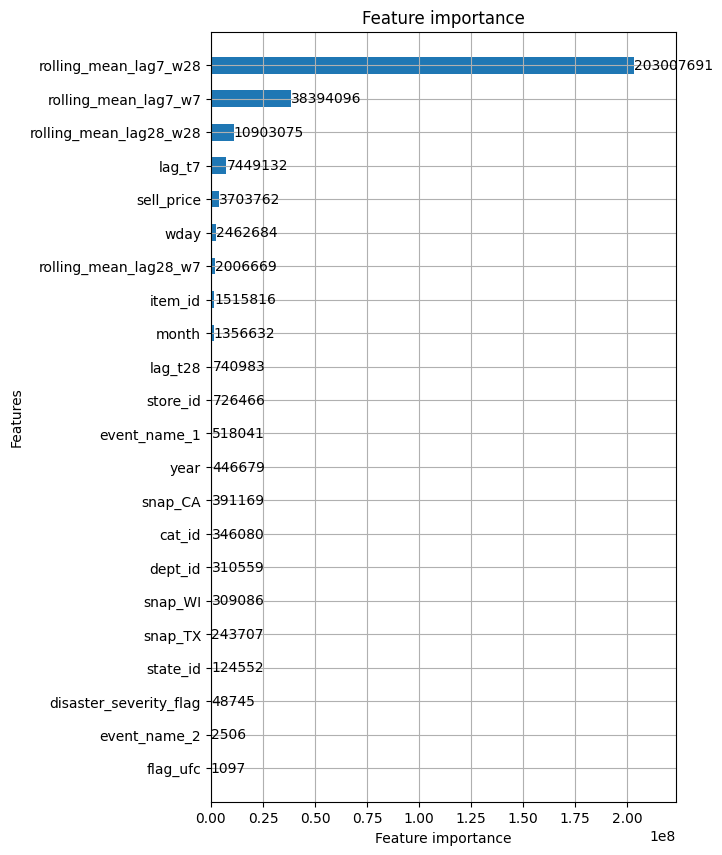

In [7]:
sample_submission = pd.read_csv('../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid,num_r):
    """ Fit LightGBM model """
     
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise' : True,
        'learning_rate' : 0.08,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row' : 0.7,
        'bagging_freq' : 1,
        'colsample_bytree': 0.7
    }

    fit = lgb.train(params, 
                    train, 
                    num_boost_round = num_r, 
                    valid_sets = [valid], 
                    early_stopping_rounds = 200,
                    verbose_eval = 100)
    
    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10));
    
    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x = prep_train(df, 1000 - 28)
del df
gc.collect()
fit = fit_model(train, valid,700)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="submission.csv")

In [2]:
print(len(data['id']))
minh = len(data['id'])/3
print(minh)

28691090
9563696.666666666


In [9]:
df['disaster_severity_flag'].unique()

array([0], dtype=int8)

In [ ]:
# done_gold = pd.read_parquet('../data/done_gold.parquet')
# done_ufc = pd.read_parquet('../data/done_ufc.parquet')

In [ ]:
# print(done_gold.columns)
# print(done_ufc.columns)
# df = df.merge(done_gold[['date', 'gold_price']], on='date', how='left')

Index(['date', 'gold_price'], dtype='object')
Index(['date', 'event_state'], dtype='object')


In [ ]:
# done_ufc['event_state'].unique()
# mapping = {
#     'California': 1,
#     'Texas': 2,
#     'Wisconsin': 3
# }

# done_ufc['event_state'] = done_ufc['event_state'].replace(mapping).astype('int16')
# done_ufc['event_state'].unique()
# done_ufc = done_ufc.rename(columns={'event_state': 'state_id'})
# done_ufc['flag_ufc'] = 1
# done_ufc.to_parquet('../data/done_ufc.parquet')

In [ ]:
# print(done_ufc.columns)
# done_ufc.head()
# df['flag_ufc'] = df.merge(
#     done_ufc[['state_id', 'date']].drop_duplicates(), 
#     on=['state_id', 'date'], 
#     how='left', 
#     indicator=True
# )['_merge'].eq('both').astype('int8')
# df['flag_ufc'].unique()

Index(['date', 'state_id', 'flag_ufc'], dtype='object')


array([0, 1], dtype=int8)

In [ ]:
# print(len(df['disaster_severity_flag']))
# grid_df = df[:][:27837370].dropna(subset=['demand'])
# print(len(grid_df['disaster_severity_flag']))
# del df
# gc.collect()

In [3]:
# grid_df

In [4]:
# print(grid_df.columns)

In [5]:
# m = grid_df.id=='HOBBIES_1_288_CA_1'
# sales_ts = grid_df.loc[m,'demand'].values
# sales_ts

In [6]:
# def gap_finder(ts):
    
#     # this function finds gaps and calculates their length:
#     ts = (~(ts > 0)).astype(int)

#     for i, val in enumerate(ts):
#         if val == 0: 
#             continue
#         else: 
#             ts[i] += ts[i-1]
#             ts[i-1] = -1
#     return ts

# def gap_counter(ts):
    
#     # value_counts for gaps lengths
    
#     counts = np.unique(ts, return_counts=True)
#     return dict(zip(counts[0], counts[1]))

# m = grid_df.id=='HOBBIES_1_288_CA_1'

# sales_gaps = gap_counter(gap_finder(grid_df.loc[m,'demand'].values))
# sales_gaps

In [7]:
# # Lets try to build a synthetic series with gaps.
# # We assume products have a constant chance of being sold on any particular day.
# # So for every day we will flip an unfair coin with probability of sale equal to 'dates_with sale'/'all_dates'
# # >>>This might be an oversimplistic assumption, a moving window might be used instead.

# def synth_sales(gaps_dict, min_gap=1000):
    
#     sum_sale_days = gaps_dict.get(0,0) # key '0' gives number of days with sales
#     sum_days = sum(gaps_dict.values()) # sum of all keys - number of all days
    
#     # Sum of days in gaps longer than minimum gap length:
#     sum_gap_length = sum([k for k in [*sales_gaps.keys()] if k > min_gap])
    
#     # Exlude all the gaps longer than min_gap_length from probability calculation:
#     p = sum_sale_days/(sum_days-sum_gap_length)
    
#     return np.random.binomial(1, p, sum(gaps_dict.values()))

# synth_sales_gaps = gap_counter(gap_finder(synth_sales(sales_gaps)))
# synth_sales_gaps

In [8]:
# # As you can see we dont have results > 20. 
# # To make sure this is a consistent result lets run simulation 1,000 times:
# # >>>> n equal 1,000 might be an overshot for some ids.

# n=1000

# sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for i in range(n)])
# gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()
# gap_length_prob

In [9]:
# # The shortest gap that has been seen in less than 5% of simulated series:
# min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)
# min_gap_length

In [10]:
# # Now we exclude the gaps longer than min_gap_length from 'probability of sale' calculation, 
# # because we assume them to be non-random.
# # Run the simulation recursively until the min_gap_length does not decrease:

# n=1000
# new_min_gap_length = 0

# while new_min_gap_length != min_gap_length:
    
#     if new_min_gap_length!=0: min_gap_length=new_min_gap_length

#     sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for i in range(n)])
#     gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

#     # Lets find the shortes gap that has been seen in les than 5% of simulated series:
#     new_min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)

# min_gap_length

In [11]:
# # Finally we need to make a feature 'out_of_stock' for the product:
# m = grid_df.id=='HOBBIES_1_288_CA_1'
# idx = grid_df.loc[m,'demand'].index

# gf = pd.Series(gap_finder(grid_df.loc[m,'demand'].values), index = idx)
# gf = gf.replace(-1,np.nan).fillna(method='backfill') 
# gf = gf > min_gap_length
# gf

In [12]:
# from tqdm import tqdm

# grid_df['out_of_stock'] = 0

# n = 1000
# prods = list(grid_df.id.unique())
# gap_length_list = []

# for prod_id in tqdm(prods):
#     m = grid_df.id == prod_id
#     idx = grid_df.loc[m, 'demand'].index

#     demand_vals = grid_df.loc[m, 'demand'].values
#     sales_gaps = gap_counter(gap_finder(demand_vals))

#     # Nếu không có gap (tức là không có đoạn liên tiếp có demand = 0), bỏ qua
#     if len(sales_gaps) == 0:
#         continue

#     try:
#         sym_df = pd.DataFrame([
#             gap_counter(gap_finder(synth_sales(sales_gaps)))
#             for _ in range(n)
#         ])
#         gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()
#         rare_gaps = gap_length_prob[gap_length_prob < 0.05]

#         if rare_gaps.empty:
#             continue

#         min_gap_length = min(rare_gaps.index)
#         new_min_gap_length = 0

#         while new_min_gap_length < min_gap_length:
#             if new_min_gap_length != 0:
#                 min_gap_length = new_min_gap_length

#             sym_df = pd.DataFrame([
#                 gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length)))
#                 for _ in range(n)
#             ])
#             gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()
#             rare_gaps = gap_length_prob[gap_length_prob < 0.05]

#             if rare_gaps.empty:
#                 break

#             new_min_gap_length = min(rare_gaps.index)

#         # Tính khoảng cách thật từ demand
#         gf = pd.Series(gap_finder(demand_vals), index=idx)
#         gf = gf.replace(-1, np.nan).fillna(method='backfill')
#         gf = gf > min_gap_length
#         grid_df.loc[m, 'out_of_stock'] = gf.astype(int)

#         gap_length_list.append(min_gap_length)

#     except Exception as e:
#         print(f"Skipped {prod_id} due to error: {e}")
#         continue